In [ ]:
import pandas as pd

#Load your cleaned dataset
df = pd.read_csv("data/cleaned/TXRPI_cleaned.csv")

#Sort by Date and calculate Growth Rate (%)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Growth Rate"] = df["Texas_Real_Personal_Income"].pct_change() * 100

#This will Keep only Date and Growth Rate
model_df = df[["Date", "Growth Rate"]].copy()

#This will create the future column
model_df["actual_future"] = model_df["Growth Rate"].shift(-1)

#Create the persistence baseline prediction (predicting future = today's value)
model_df["baseline_prediction"] = model_df["Growth Rate"]

# This drops the rows that have missing values which would be the first row (since it has no previous value to calculate growth rate) and the last row (since it has no future value to compare against).
model_df = model_df.dropna().reset_index(drop=True)

print(model_df)


         Date  Growth Rate  actual_future  baseline_prediction
0  2009-01-01    -3.994311       3.471239            -3.994311
1  2010-01-01     3.471239       7.499089             3.471239
2  2011-01-01     7.499089       3.598257             7.499089
3  2012-01-01     3.598257       0.922765             3.598257
4  2013-01-01     0.922765       5.344590             0.922765
5  2014-01-01     5.344590       1.876083             5.344590
6  2015-01-01     1.876083      -1.116325             1.876083
7  2016-01-01    -1.116325       6.046570            -1.116325
8  2017-01-01     6.046570       4.441509             6.046570
9  2018-01-01     4.441509       2.775857             4.441509
10 2019-01-01     2.775857       2.951563             2.775857
11 2020-01-01     2.951563       7.331062             2.951563
12 2021-01-01     7.331062       1.854962             7.331062
13 2022-01-01     1.854962       4.311946             1.854962
14 2023-01-01     4.311946       2.733598             4

In [ ]:
#This will just split the data into training and testing sets, with 80% of the data for training and 20% for testing. The split is done based on the index of the DataFrame.
from email import errors

#Splits the data into training and testing sets
split_index = int(len(model_df) * 0.8)
train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

print (f"Training rows: {len(train_df)} | Testing rows: {len(test_df)}\n")

actual = test_df["actual_future"]
predicted = test_df["baseline_prediction"]
errors = actual - predicted

#Mean Absolute Error (MAE)
mae = errors.abs().mean()
#Root Mean Square Error (RMSE)
rmse = (errors ** 2).mean() ** 0.5

#Finds the coefficient of Determination which would be the R² value.
ss_res = (errors ** 2).sum()
ss_tot = ((actual - actual.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

print(f"Mean Absolute Error (MAE): {mae: .2f}")
print(f"Root Mean Square Error (RMSE): {rmse: .2f}")
print(f"R²: {r2: .2f}")


Training rows: 12 | Testing rows: 3

Mean Absolute Error (MAE):  3.17
Root Mean Square Error (RMSE):  3.58
R²: -11.42


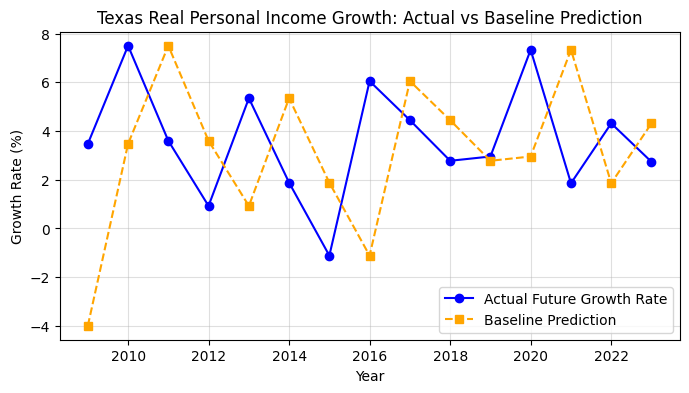

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

#Asked AI if it could add a plot of the actual future growth rate and the baseline prediction to visualize how well the baseline prediction is performing. The AI suggested the following code to create the plot:
plt.plot(model_df["Date"], model_df["actual_future"], marker="o", linestyle="-", color="blue", label="Actual Future Growth Rate")
plt.plot(model_df["Date"], model_df["baseline_prediction"], marker="s", linestyle="--", color="orange", label="Baseline Prediction")

plt.title("Texas Real Personal Income Growth: Actual vs Baseline Prediction")
plt.xlabel("Year")
plt.ylabel("Growth Rate (%)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()